# Tutorial 1A: DDPM
In this lab, a diffusion model uses a UNet to process the input and produce the output at each step.


In [11]:
!pip install ipywidgets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 17.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ipywidgets]


In [1]:
import torch

device = torch.accelerator.current_accelerator() if torch.accelerator.is_available() else "cpu"
print(device)

mps


In [2]:
import torch
from diffusers import UNet2DModel

model = UNet2DModel(
    sample_size=128,  # the target image resolution
    in_channels=3,  # the number of input channels, 3 for RGB images
    out_channels=3,  # the number of output channels
    layers_per_block=2,  # how many ResNet layers to use per UNet block
    block_out_channels=(128, 128, 256, 256, 512, 512),  # the number of output channels for each UNet block
    down_block_types=(
        "DownBlock2D",  # a regular ResNet downsampling block
        "DownBlock2D",
        "DownBlock2D",
        "DownBlock2D",
        "AttnDownBlock2D",  # a ResNet downsampling block with spatial self-attention
        "DownBlock2D",
    ),
    up_block_types=(
        "UpBlock2D",  # a regular ResNet upsampling block
        "AttnUpBlock2D",  # a ResNet upsampling block with spatial self-attention
        "UpBlock2D",
        "UpBlock2D",
        "UpBlock2D",
        "UpBlock2D",
    ),
).to(device)

print(model)

UNet2DModel(
  (conv_in): Conv2d(3, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (time_proj): Timesteps()
  (time_embedding): TimestepEmbedding(
    (linear_1): Linear(in_features=128, out_features=512, bias=True)
    (act): SiLU()
    (linear_2): Linear(in_features=512, out_features=512, bias=True)
  )
  (down_blocks): ModuleList(
    (0-1): 2 x DownBlock2D(
      (resnets): ModuleList(
        (0-1): 2 x ResnetBlock2D(
          (norm1): GroupNorm(32, 128, eps=1e-05, affine=True)
          (conv1): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (time_emb_proj): Linear(in_features=512, out_features=128, bias=True)
          (norm2): GroupNorm(32, 128, eps=1e-05, affine=True)
          (dropout): Dropout(p=0.0, inplace=False)
          (conv2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (nonlinearity): SiLU()
        )
      )
      (downsamplers): ModuleList(
        (0): Downsample2D(
          (conv): Con

For training a diffusion model, in each iteration, we need a random noise which will be added to the training sample image.

In [3]:
import torch
from PIL import Image
from diffusers import DDPMScheduler

# fake training sample image, you can load your own
sample_image = torch.randn([1, 3, 128, 128], device=device)

noise_scheduler = DDPMScheduler(num_train_timesteps=1000)
noise = torch.randn_like(sample_image)
# in each training iteration, sample a 't' value.
# here we use 50 as an example
timesteps = torch.tensor([50], dtype=torch.long, device=device)
noisy_image = noise_scheduler.add_noise(sample_image, noise, timesteps)

The training objective of the model is to predict the noise added to the image. The loss at this step can be calculated by:


In [25]:
import torch.nn.functional as F
with torch.no_grad():
    noise_pred = model(noisy_image, timesteps).sample
loss = F.mse_loss(noise_pred, noise)
print(f"Loss: {loss.item()}")

Loss: 1.1137927770614624


The training of a diffusion model is very time-consuming. If you are interested in training a diffusion model from scratch by yourself, please refer to https://huggingface.co/docs/diffusers/en/tutorials/basic_training.
DDPMPipeline can be applied to sample synthetic images according to the trained unet and the model configuration.

Using device: mps


  0%|          | 0/1000 [00:00<?, ?it/s]

DDPM, 1000 steps: 34.01 seconds


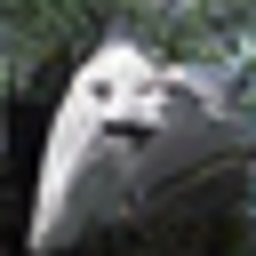

In [4]:
from diffusers import DDPMPipeline, DDPMScheduler, UNet2DModel
from IPython.display import display

# google/ddpm-cifar10-32    google/ddpm-church-256
repo_id = "google/ddpm-cifar10-32"

# loading a pretrained unet
unet = UNet2DModel.from_pretrained(repo_id, use_safetensors=True).eval()
# loading the corresponding training configuration
scheduler = DDPMScheduler.from_pretrained(repo_id)

ddpm_pipe = DDPMPipeline(unet, scheduler)

device = torch.accelerator.current_accelerator() if torch.accelerator.is_available() else "cpu"
print(f"Using device: {device}")
ddpm_pipe.to(device)

import time
if device.type == "cuda":
    torch.cuda.synchronize()
elif device.type == "mps":
    torch.mps.synchronize()
    
start = time.perf_counter()
res = ddpm_pipe(generator=torch.Generator().manual_seed(42)) # only generating a random number can be done with cpu.
if device.type == "cuda":
    torch.cuda.synchronize()
elif device.type == "mps":
    torch.mps.synchronize()
print(f"DDPM, 1000 steps: {time.perf_counter() - start:.2f} seconds")
image = res.images[0]

display(image.resize((256, 256)))

We can also do the sampling step by step using the following code.

Using device: mps
torch.Size([1, 3, 32, 32])
Denoising for 100 timesteps...


7it [00:01,  9.21it/s]

'Image at step 10'

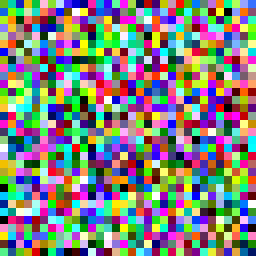

18it [00:01, 18.30it/s]

'Image at step 20'

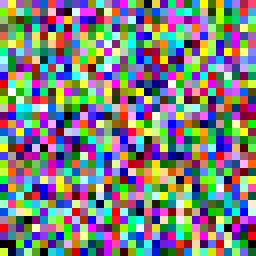

27it [00:01, 21.31it/s]

'Image at step 30'

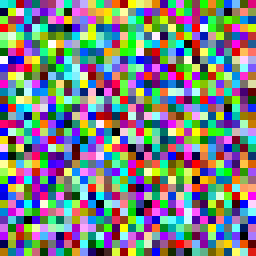

39it [00:02, 22.13it/s]

'Image at step 40'

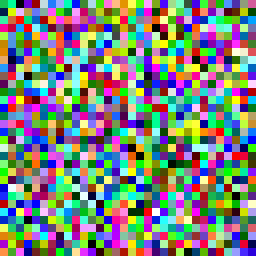

48it [00:02, 23.58it/s]

'Image at step 50'

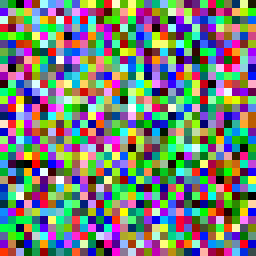

57it [00:03, 24.42it/s]

'Image at step 60'

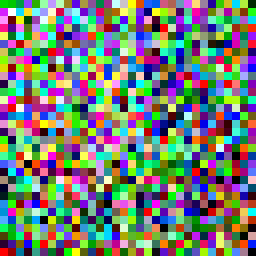

69it [00:03, 24.34it/s]

'Image at step 70'

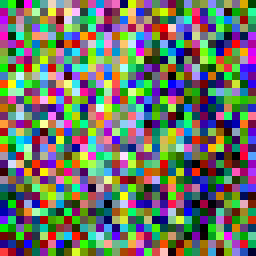

78it [00:04, 24.54it/s]

'Image at step 80'

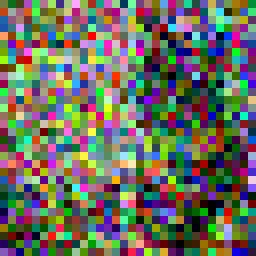

87it [00:04, 24.83it/s]

'Image at step 90'

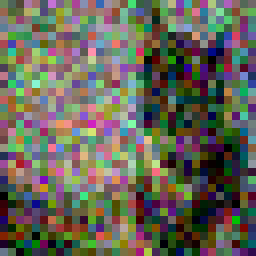

99it [00:04, 25.12it/s]

'Image at step 100'

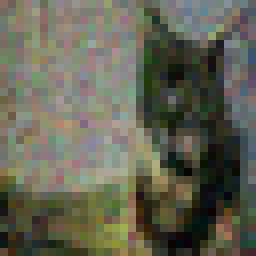

100it [00:04, 20.14it/s]


In [32]:
import PIL.Image
import numpy as np
import torch
from tqdm import tqdm

def display_sample(sample, i, display_size=256):
    if isinstance(sample, PIL.Image.Image):
        image_pil = sample
    else:
        pixels = sample.detach().cpu().clamp(-1, 1)
        pixels = pixels.permute(0, 2, 3, 1)
        pixels = ((pixels + 1) * 127.5).numpy().astype(np.uint8)
        image_pil = PIL.Image.fromarray(pixels[0])

    image_pil = image_pil.resize(
        (display_size, display_size),
        resample=PIL.Image.Resampling.NEAREST,
    )
    display(f"Image at step {i}")
    display(image_pil)

device = torch.device(torch.accelerator.current_accelerator() if torch.accelerator.is_available() else "cpu")
print(f"Using device: {device}")
unet.to(device)
scheduler.set_timesteps(100, device=device)

noisy_sample=torch.randn(1, unet.config.in_channels, unet.config.sample_size,
                         unet.config.sample_size).to(device)

print(noisy_sample.shape)

sample=noisy_sample

print(f"Denoising for {len(scheduler.timesteps)} timesteps...")
for i, t in tqdm(enumerate(scheduler.timesteps)):
    # t is already on the correct device now
    with torch.no_grad():
        residual=unet(sample,t).sample

    # compute less noisy image and set x_t -> x_t-1
    sample =scheduler.step(residual, t, sample).prev_sample

    if (i+1)%10==0:
        display_sample(sample, i+1)

# Tutorial 1B: DDIM question
DDIM can use the same trained U-Net with fewer sampling steps. With `eta=0`, sampling is deterministic for a fixed initial noise tensor, and thus also invertible.

**Exercise:** Compare 50 and 10 DDIM steps with the DDPM result above. What changes in the image and sampling time? Why can we keep the same U-Net? Keep the seed fixed; one image is only an illustration of quality.

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 10/10 [00:00<00:00, 25.87it/s]

DDIM, 10 steps: 0.39 seconds


'Image at step 10'

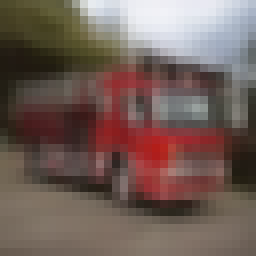

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 20/20 [00:00<00:00, 29.56it/s]

DDIM, 20 steps: 0.68 seconds


'Image at step 20'

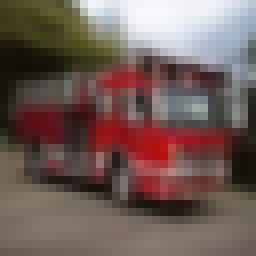

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 30/30 [00:00<00:00, 30.89it/s]


DDIM, 30 steps: 0.98 seconds


'Image at step 30'

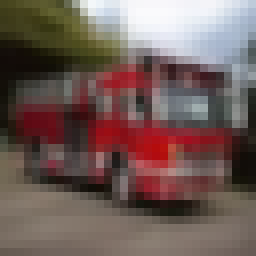

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 40/40 [00:01<00:00, 30.82it/s]

DDIM, 40 steps: 1.30 seconds


'Image at step 40'

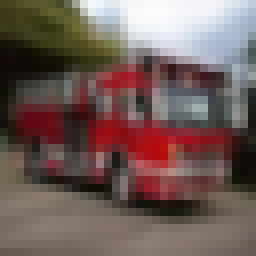

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 50/50 [00:01<00:00, 30.51it/s]

DDIM, 50 steps: 1.65 seconds


'Image at step 50'

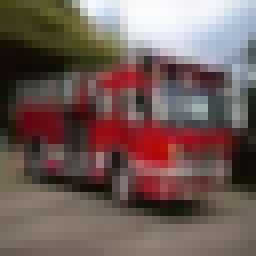

In [33]:
from diffusers import DDIMPipeline, DDIMScheduler
import time

ddim_scheduler = DDIMScheduler.from_config(scheduler.config)
ddim_pipe = DDIMPipeline(unet=unet, scheduler=ddim_scheduler).to(device)
for steps in [10, 20, 30, 40, 50]:
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()
    start = time.perf_counter()
    res = ddim_pipe(num_inference_steps=steps, eta=0.0,
                    generator=torch.Generator(device=device).manual_seed(42))
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()
    print(f"DDIM, {steps} steps: {time.perf_counter() - start:.2f} seconds")
    display_sample(res.images[0],i=steps)

**Your answer:** Add your observations here.¨

We observe more details over higher steps, but this comes with a higher sampling time. <br>
Here we need to chose between processing speed or image quality. What we choose will depend on our application.

[DDIM scheduler reference](https://huggingface.co/docs/diffusers/api/schedulers/ddim).